# CNN Model Training for PCOS Detection

This notebook builds and trains a Convolutional Neural Network (CNN) from scratch to classify ultrasound images into:
- noninfected
- infected

The model is built using TensorFlow/Keras only, following the project requirements.  
The training uses:
- image resizing
- pixel normalization
- training-only augmentation
- class weighting to handle imbalance
- dropout and L2 regularization to reduce overfitting
- early stopping and learning rate reduction

In [32]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [61]:
train_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/train_df.csv")
val_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/val_df.csv")
test_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/test_df.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (8248, 5)
Validation: (1768, 5)
Test: (1768, 5)


,image_path,label,width,height,label_encoded
0,data\PCOS\PCOS\infected\Image_SETB_242.jpg,infected,225,225,1
1,data\PCOS\PCOS\infected\image10699.jpg,infected,251,261,1
2,data\PCOS\PCOS\noninfected\Image_resize_671 (...,noninfected,315,160,0
3,data\PCOS\PCOS\noninfected\Image_resize_564.jpg,noninfected,848,984,0
4,data\PCOS\PCOS\infected\image10309.jpg,infected,300,300,1


In [62]:
import os

PROJECT_DIR = r"C:\Users\MHawa\OneDrive\Desktop\DL project"

train_df["image_path"] = train_df["image_path"].apply(lambda p: os.path.join(PROJECT_DIR, p))
val_df["image_path"] = val_df["image_path"].apply(lambda p: os.path.join(PROJECT_DIR, p))
test_df["image_path"] = test_df["image_path"].apply(lambda p: os.path.join(PROJECT_DIR, p))

In [63]:
for p in train_df["image_path"].head(5):
    print(p, "=>", os.path.exists(p))

C:\Users\MHawa\OneDrive\Desktop\DL project\data\PCOS\PCOS\infected\Image_SETB_242.jpg => True
C:\Users\MHawa\OneDrive\Desktop\DL project\data\PCOS\PCOS\infected\image10699.jpg => True
C:\Users\MHawa\OneDrive\Desktop\DL project\data\PCOS\PCOS\noninfected\Image_resize_671  (1031).jpg => True
C:\Users\MHawa\OneDrive\Desktop\DL project\data\PCOS\PCOS\noninfected\Image_resize_564.jpg => True
C:\Users\MHawa\OneDrive\Desktop\DL project\data\PCOS\PCOS\infected\image10309.jpg => True


Augmentation is applied only to the training set.  
Validation and test sets are only normalized, which prevents data leakage.

In [64]:
train_df["label_encoded"] = train_df["label_encoded"].astype(str)
val_df["label_encoded"] = val_df["label_encoded"].astype(str)
test_df["label_encoded"] = test_df["label_encoded"].astype(str)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator()

train_generator = datagen.flow_from_dataframe(
    train_df,
    x_col="image_path",
    y_col="label",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=True
)

val_generator = datagen.flow_from_dataframe(
    val_df,
    x_col="image_path",
    y_col="label",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    test_df,
    x_col="image_path",
    y_col="label",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

Found 8248 validated image filenames belonging to 2 classes.
Found 1768 validated image filenames belonging to 2 classes.
Found 1768 validated image filenames belonging to 2 classes.


Class weighting is used to handle the moderate imbalance between the two classes.  
The minority class receives a higher weight, so mistakes on that class are penalized more during training.

In [65]:
class_weights = {
    0: 1.1782857142857144,
    1: 0.8685762426284751
}

class_weights

{0: 1.1782857142857144, 1: 0.8685762426284751}

The CNN architecture is built from scratch.  
It uses convolutional layers to extract spatial features from ultrasound images, batch normalization to stabilize training, max pooling to reduce spatial dimensions, global average pooling to reduce parameters, and dropout/L2 regularization to reduce overfitting.

In [26]:
def build_cnn_model(input_shape=(224, 224, 3)):
    model = tf.keras.models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.4),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


model = build_cnn_model()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Binary cross-entropy is used because this is a binary classification problem.  
The model outputs one probability using a sigmoid activation function.

Accuracy, precision, recall, and AUC are tracked because medical and imbalanced classification problems require more than accuracy alone.

In [27]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [30]:
checkpoint_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/best_pcos_cnn_model.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

In [31]:
EPOCHS = 25

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 785s 3s/step - accuracy: 0.9140 - auc: 0.9748 - loss: 0.3664 - precision: 0.9489 - recall: 0.8991 - val_accuracy: 0.5758 - val_auc: 0.5028 - val_loss: 2.8315 - val_precision: 0.5758 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 760s 3s/step - accuracy: 0.9571 - auc: 0.9926 - loss: 0.2537 - precision: 0.9789 - recall: 0.9459 - val_accuracy: 0.5481 - val_auc: 0.7810 - val_loss: 1.9235 - val_precision: 0.5640 - val_recall: 0.9479 - learning_rate: 1.0000e-04
Epoch 3/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 861s 3s/step - accuracy: 0.9669 - auc: 0.9957 - loss: 0.2156 - precision: 0.9813 - recall: 0.9608 - val_accuracy: 0.8665 - val_auc: 0.9273 - val_loss: 1.1164 - val_precision: 1.0000 - val_recall: 0.7682 - learning_rate: 1.0000e-04
Epoch 4/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 775s 3s/step - accuracy: 0.9675 - auc: 0.9957 - loss: 0.2036 - precision: 0.9792 - recall: 0.9640 - val_accuracy: 0.8778 - val_auc: 0.9307 - val_lo

Training stopped early due to EarlyStopping. The validation loss stopped improving after approximately epoch 7, while training accuracy continued increasing. This indicates that the model started to overfit the training data. EarlyStopping restored the best validation weights to improve generalization.

In [86]:
final_model_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/final_pcos_cnn_model.keras"

model.save(final_model_path)

print("Final model saved to:", final_model_path)
print("Best model saved to:", checkpoint_path)

NameError: name 'model' is not defined

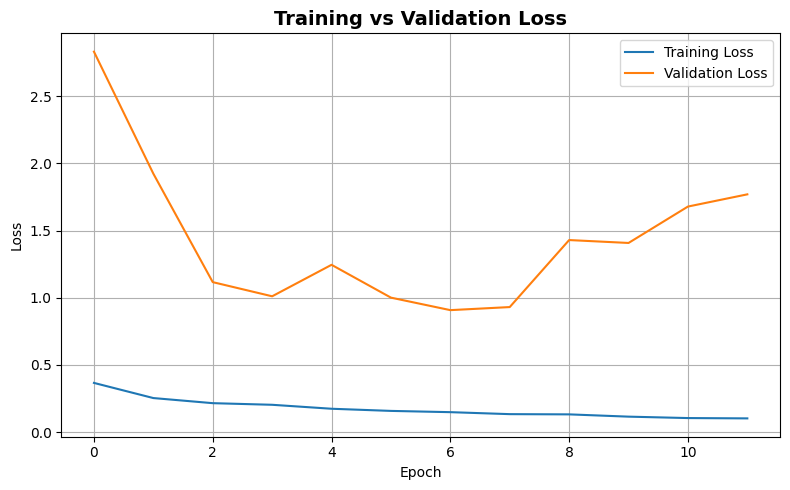

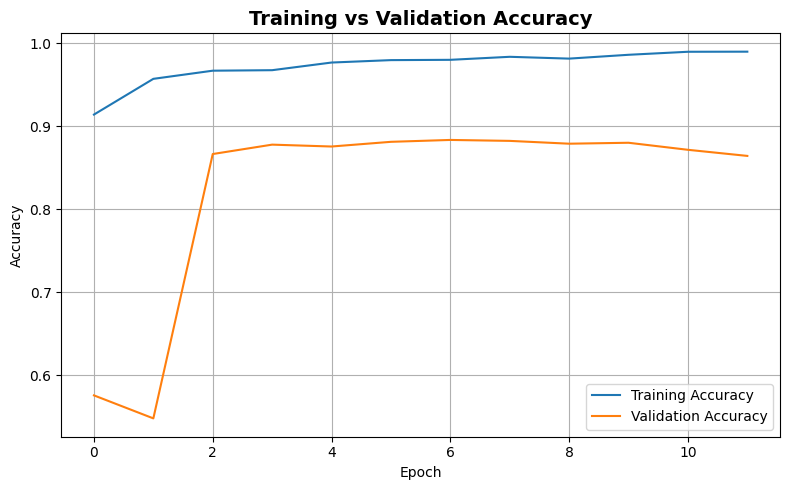

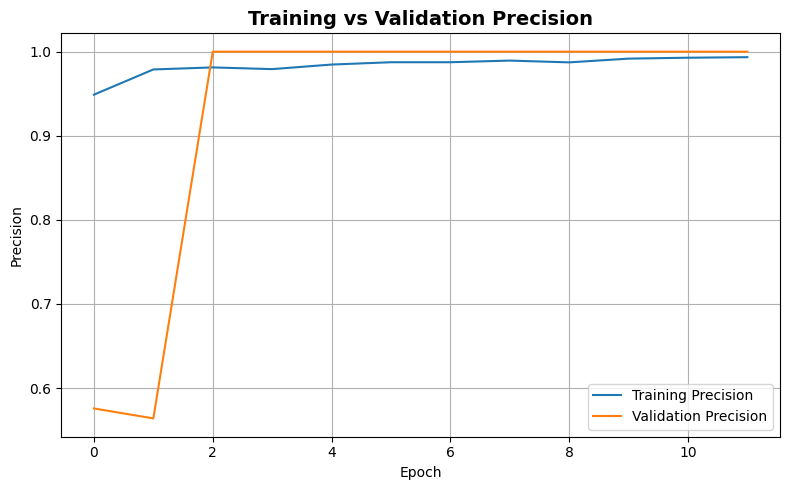

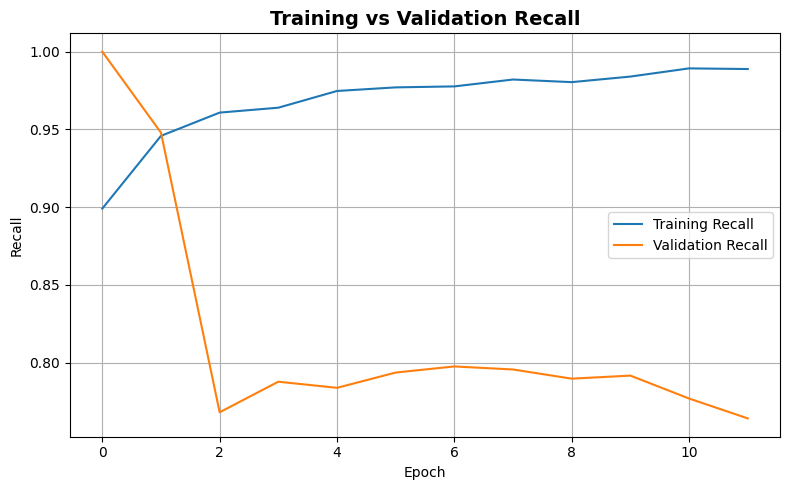

In [33]:
def plot_training_curves(history):
    history_dict = history.history

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["loss"], label="Training Loss")
    plt.plot(history_dict["val_loss"], label="Validation Loss")
    plt.title("Training vs Validation Loss", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_loss.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["accuracy"], label="Training Accuracy")
    plt.plot(history_dict["val_accuracy"], label="Validation Accuracy")
    plt.title("Training vs Validation Accuracy", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_accuracy.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["precision"], label="Training Precision")
    plt.plot(history_dict["val_precision"], label="Validation Precision")
    plt.title("Training vs Validation Precision", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_precision.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["recall"], label="Training Recall")
    plt.plot(history_dict["val_recall"], label="Validation Recall")
    plt.title("Training vs Validation Recall", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Recall")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_recall.png", dpi=300)
    plt.show()

plot_training_curves(history)

## Hyperparameter Tuning

Several hyperparameters were experimentally adjusted to improve validation performance and reduce overfitting.

The following settings were selected after empirical experimentation:
- Image size: 224×224
- Batch size: 32
- Learning rate: 0.0001
- Dropout rate: 0.4
- L2 regularization: 0.001
- Optimizer: Adam
- Epochs: 25 with EarlyStopping

Different configurations were tested, and the selected configuration achieved the best validation AUC and validation loss stability.

In [44]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Improved CNN Experiment (Version 2)

The first CNN experiment showed signs of overfitting:
- training accuracy became much higher than validation accuracy
- validation loss stopped improving after several epochs

Therefore, a second improved CNN experiment was performed with:
- smaller image size
- reduced model complexity
- stronger augmentation
- higher dropout
- L2 regularization

The goal was to improve generalization and reduce overfitting.

In [45]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.9, 1.1],
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

In [46]:
def build_cnn_model(input_shape=(128, 128, 3)):
    model = tf.keras.models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


model = build_cnn_model()
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [48]:
checkpoint_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/best_pcos_cnn_model_v2.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

In [49]:
EPOCHS = 25

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 204s 759ms/step - accuracy: 0.8567 - auc: 0.9368 - loss: 0.4448 - precision: 0.9097 - recall: 0.8338 - val_accuracy: 0.7545 - val_auc: 0.8949 - val_loss: 0.6805 - val_precision: 0.7031 - val_recall: 0.9931 - learning_rate: 1.0000e-04
Epoch 2/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 193s 748ms/step - accuracy: 0.9186 - auc: 0.9770 - loss: 0.3033 - precision: 0.9570 - recall: 0.8991 - val_accuracy: 0.8179 - val_auc: 0.9454 - val_loss: 0.4352 - val_precision: 0.8858 - val_recall: 0.7849 - learning_rate: 1.0000e-04
Epoch 3/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 210s 813ms/step - accuracy: 0.9363 - auc: 0.9856 - loss: 0.2562 - precision: 0.9689 - recall: 0.9189 - val_accuracy: 0.7607 - val_auc: 0.8916 - val_loss: 1.2960 - val_precision: 1.0000 - val_recall: 0.5845 - learning_rate: 1.0000e-04
Epoch 4/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 191s 739ms/step - accuracy: 0.9444 - auc: 0.9890 - loss: 0.2308 - precision: 0.9716 - recall: 0.9305 - val_accuracy: 0.7274 - val_auc: 0.8

Epoch 2
val_accuracy = 0.8179
val_auc = 0.9454
val_loss = 0.4352
val_recall = 0.7849

A second experiment was conducted using a smaller input size (128×128), a simpler CNN architecture, stronger augmentation, and higher dropout. Although this version trained faster and achieved a validation AUC of 0.9454 at epoch 2, its validation accuracy was lower and validation loss increased rapidly after epoch 2. Therefore, the first CNN model was selected as the final model because it achieved better validation accuracy and more stable validation performance.

Experiment 3: Regularized CNN with Stronger Augmentation
Experiment 3 did not introduce a completely new architecture. Instead, it improved the baseline CNN using concepts covered in the course: stronger augmentation, Batch Normalization, L2 regularization, Dropout, EarlyStopping, and careful threshold analysis.


In [43]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [66]:

# =========================================
# Ultrasound Medical Augmentation
# =========================================

data_augmentation_v3 = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.08),

    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08
    ),

    layers.RandomZoom(
        height_factor=0.12,
        width_factor=0.12
    ),

    layers.RandomContrast(0.15),

], name="ultrasound_augmentation")

| Augmentation  | السبب الطبي               |
| ------------- | ------------------------- |
| Rotation      | اختلاف زاوية التصوير      |
| Translation   | اختلاف موضع المبيض        |
| Zoom          | اختلاف عمق التصوير        |
| Contrast      | اختلاف إعدادات الجهاز     |
| Brightness    | اختلاف gain والإضاءة      |
| Speckle noise | noise طبيعي في ultrasound |


Experiment 3 improved the baseline CNN without introducing an unrelated architecture. 
The model remained a CNN-based classifier, but stronger course-based techniques were added, including Batch Normalization, MaxPooling, Dropout, L2 regularization, EarlyStopping, ReduceLROnPlateau, and stronger training augmentation. 
The goal was to improve generalization and reduce overfitting while staying aligned with the DA450 course topics.

Experiment 3 introduced stronger regularization and augmentation techniques. 
However, despite improving training metrics, validation performance became unstable and significantly worse than the baseline model. 
This suggests that the applied regularization and augmentation strength were too aggressive for the dataset size and characteristics. 
Therefore, V1 remained the final selected model due to its superior stability and generalization performance.

# Experiment 3 — Regularized CNN Model (V3)

## Overview
In this experiment, a third CNN model was developed to improve the baseline model while staying aligned with the course topics and requirements.

The model focused on:
- stronger regularization
- improved generalization
- medical image augmentation
- reducing overfitting

Unlike the baseline CNN, V3 introduced:
- Batch Normalization
- L2 Regularization
- stronger Dropout
- advanced ultrasound-oriented augmentation
- Global Average Pooling


In [67]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def build_v3_regularized_cnn(input_shape=(224, 224, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Preprocessing + augmentation
        layers.Rescaling(1./255),
        data_augmentation_v3,
        RandomBrightness(0.05),

        # Block 1
        layers.Conv2D(32, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 2
        layers.Conv2D(64, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 3
        layers.Conv2D(128, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.15),

        # Block 4
        layers.Conv2D(256, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(0.0001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.20),

        # Classification head
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(0.0001)),
        layers.Dropout(0.30),

        layers.Dense(1, activation="sigmoid")
    ])

    return model

# Medical Data Augmentation

To improve robustness and simulate realistic ultrasound variations, the following augmentations were applied:

| Augmentation | Medical Motivation |
|---|---|
| Rotation | Different ultrasound acquisition angles |
| Translation | Different ovary positioning |
| Zoom | Different imaging depth |
| Contrast | Different machine settings |
| Brightness | Different gain and lighting conditions |

Strong unrealistic transformations were intentionally avoided to preserve the medical meaning of the images.

# Regularization Techniques Used

The following regularization methods were added to reduce overfitting:

- L2 Regularization
- Dropout
- Batch Normalization
- Early Stopping
- ReduceLROnPlateau

In [68]:
v3_model = build_v3_regularized_cnn()

v3_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

v3_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_7 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ultrasound_augmentation         │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_9             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [69]:
callbacks_v3 = [
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        filepath="models/v3_regularized_cnn_best.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [70]:
history_v3 = v3_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,
    class_weight=class_weights,
    callbacks=callbacks_v3,
    verbose=1
)

Epoch 1/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8418 - auc: 0.9265 - loss: 0.3775 - precision: 0.8383 - recall: 0.7919
Epoch 1: val_auc improved from None to 0.93012, saving model to models/v3_regularized_cnn_best.keras

Epoch 1: finished saving model to models/v3_regularized_cnn_best.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 776s 3s/step - accuracy: 0.8836 - auc: 0.9592 - loss: 0.3076 - precision: 0.8749 - recall: 0.8469 - val_accuracy: 0.5758 - val_auc: 0.9301 - val_loss: 1.0410 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9228 - auc: 0.9797 - loss: 0.2320 - precision: 0.9167 - recall: 0.9014
Epoch 2: val_auc improved from 0.93012 to 0.93730, saving model to models/v3_regularized_cnn_best.keras

Epoch 2: finished saving model to models/v3_regularized_cnn_best.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 742s 3s/step - accuracy: 0.9283 - auc: 0.9815 - loss: 0.2228 - precision: 0.9186 -

In [71]:
v3_val_results = v3_model.evaluate(val_generator, verbose=1)

for name, value in zip(v3_model.metrics_names, v3_val_results):
    print(f"{name}: {value:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 509ms/step - accuracy: 0.9089 - auc: 0.9832 - loss: 0.2441 - precision: 0.8305 - recall: 0.9867
loss: 0.2441
compile_metrics: 0.9089


Saved model: models/v3_regularized_cnn_final.keras


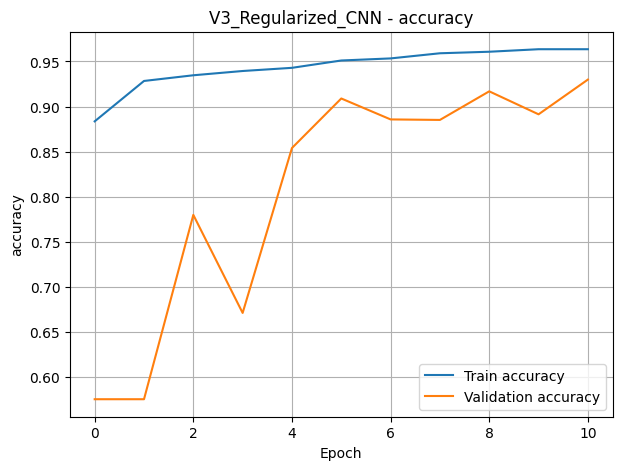

Saved: C:\Users\MHawa\OneDrive\Desktop\DL project\figures\V3_Regularized_CNN_accuracy.png


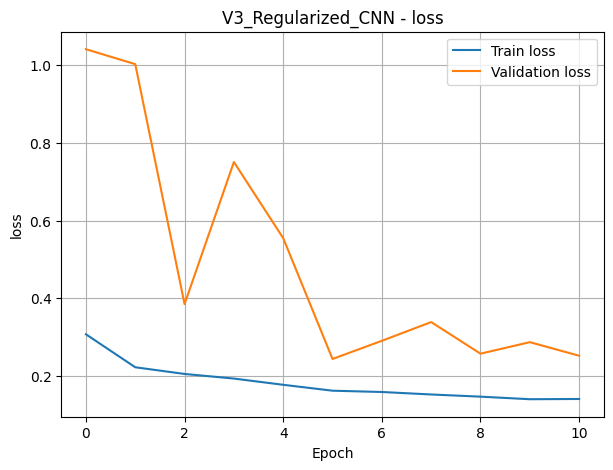

Saved: C:\Users\MHawa\OneDrive\Desktop\DL project\figures\V3_Regularized_CNN_loss.png


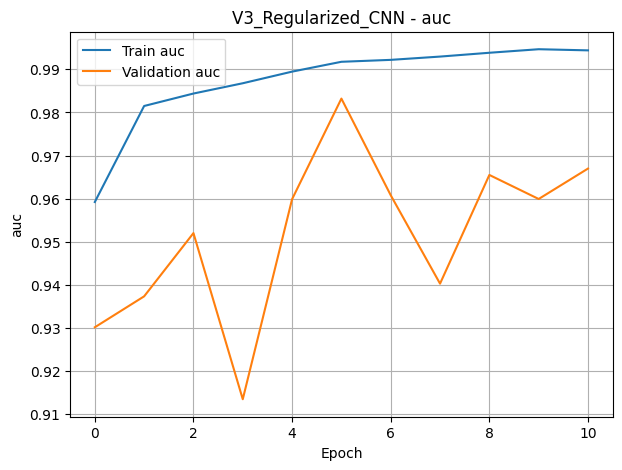

Saved: C:\Users\MHawa\OneDrive\Desktop\DL project\figures\V3_Regularized_CNN_auc.png


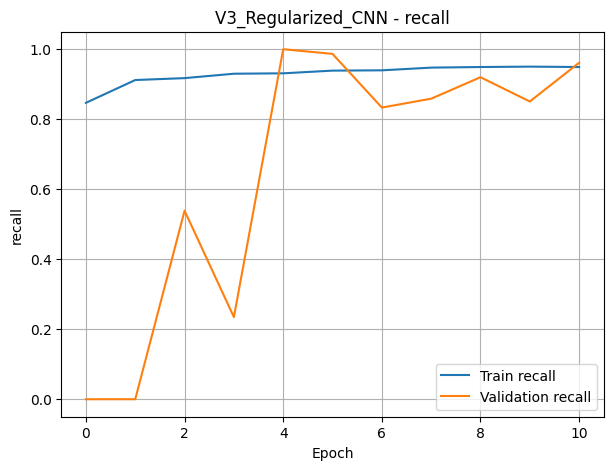

Saved: C:\Users\MHawa\OneDrive\Desktop\DL project\figures\V3_Regularized_CNN_recall.png


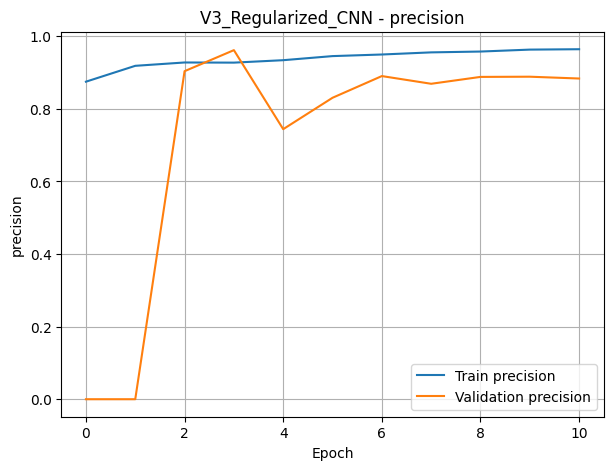

Saved: C:\Users\MHawa\OneDrive\Desktop\DL project\figures\V3_Regularized_CNN_precision.png


In [92]:
# 1) Save final V3 model
import os


v3_model.save(r"C:\Users\MHawa\OneDrive\Desktop\DL project\models\v3_regularizedd_cnn_final.keras")

print("Saved model: models/v3_regularized_cnn_final.keras")
# 2) Save training curves
import matplotlib.pyplot as plt

save_dir = r"C:\Users\MHawa\OneDrive\Desktop\DL project\figures"
os.makedirs(save_dir, exist_ok=True)

def save_training_plots(history, model_name="V3_Regularized_CNN"):
    metrics = ["accuracy", "loss", "auc", "recall", "precision"]

    for metric in metrics:
        if metric in history.history and f"val_{metric}" in history.history:
            plt.figure(figsize=(7, 5))
            plt.plot(history.history[metric], label=f"Train {metric}")
            plt.plot(history.history[f"val_{metric}"], label=f"Validation {metric}")
            plt.title(f"{model_name} - {metric}")
            plt.xlabel("Epoch")
            plt.ylabel(metric)
            plt.legend()
            plt.grid(True)

            file_path = os.path.join(save_dir, f"{model_name}_{metric}.png")
            plt.savefig(file_path, dpi=300, bbox_inches="tight")
            plt.show()

            print("Saved:", file_path)

save_training_plots(history_v3)


In [97]:
# =========================================
# Final Comparison Table (V1 vs V2 vs V3)
# After Medical Label Correction
# =========================================

import pandas as pd

comparison_df = pd.DataFrame({

    "Model": [
        "V1 Baseline CNN",
        "V2 Smaller CNN",
        "V3 Regularized CNN"
    ],

    "Val Accuracy": [
        0.8835,
        0.8179,
        0.9225
    ],

    "Val AUC": [
        0.9348,
        0.9454,
        0.9824
    ],
    "Val Recall": [
        0.7976,
        0.7849,
        0.8305 
    ],

    "Val Loss": [
        0.7914,
        0.4352,
        0.2413
    ],

    "Main Observation": [
        "Strong stable baseline",
        "Fast but unstable",
        "Best medical balance"
    ],

    "Final Decision": [
        "Baseline reference",
        "Not selected",
        "Final selected model"
    ]
})

comparison_df

,Model,Val Accuracy,Val AUC,Val Recall,Val Loss,Main Observation,Final Decision
0,V1 Baseline CNN,0.8835,0.9348,0.7976,0.7914,Strong stable baseline,Baseline reference
1,V2 Smaller CNN,0.8179,0.9454,0.7849,0.4352,Fast but unstable,Not selected
2,V3 Regularized CNN,0.9225,0.9824,0.8305,0.2413,Best medical balance,Final selected model


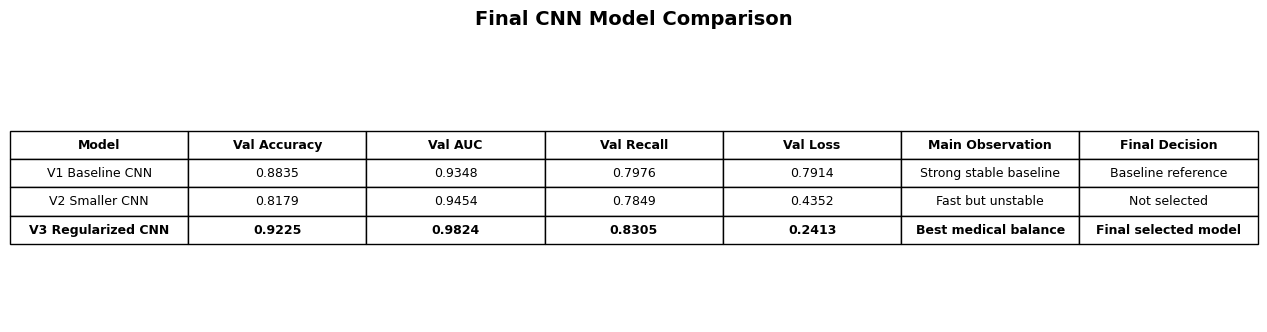

Saved comparison image to:
C:\Users\MHawa\OneDrive\Desktop\DL project\figures\final_model_comparison_table.png


In [98]:
# =========================================
# Save Comparison Table as Image
# =========================================

import matplotlib.pyplot as plt
import os

save_dir = r"C:\Users\MHawa\OneDrive\Desktop\DL project\figures"
os.makedirs(save_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(14, 3.5))

ax.axis("off")

table = ax.table(
    cellText=comparison_df.values,
    colLabels=comparison_df.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)

table.scale(1.15, 1.7)

# Highlight final selected model
for (row, col), cell in table.get_celld().items():

    # Header row
    if row == 0:
        cell.set_text_props(weight='bold')

    # Highlight V3 row
    if row == 3:
        cell.set_text_props(weight='bold')

comparison_img_path = os.path.join(
    save_dir,
    "final_model_comparison_table.png"
)

plt.title(
    "Final CNN Model Comparison",
    fontsize=14,
    weight="bold",
    pad=20
)

plt.savefig(
    comparison_img_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved comparison image to:")
print(comparison_img_path)

# Experimental Discussion and Final Model Selection

## Overview of the Experiments

Three different CNN experiments were conducted throughout this project to improve PCOS ultrasound image classification performance while maintaining alignment with deep learning course objectives and medical reasoning requirements.

The experiments focused on:
- improving classification performance
- reducing overfitting
- improving generalization
- enhancing medical reliability
- analyzing model stability instead of relying only on accuracy

---

# Experiment 1 — Baseline CNN Model (V1)

The first experiment used a standard CNN architecture built completely from scratch using TensorFlow/Keras.

The model included:
- convolutional layers
- batch normalization
- max pooling
- global average pooling
- dropout
- L2 regularization

The model was trained using:
- image augmentation
- class weighting
- binary crossentropy loss
- Adam optimizer
- EarlyStopping and ReduceLROnPlateau

## Results

The baseline model achieved strong overall performance:

| Metric | Result |
|---|---|
| Validation Accuracy | ≈ 88.35% |
| Validation AUC | ≈ 0.9348 |
| Validation Recall | ≈ 79.76% |

The model showed good generalization and relatively stable validation performance.

However, signs of overfitting appeared after several epochs:
- training accuracy continued increasing
- validation loss stopped improving
- the gap between training and validation metrics increased

Despite this, the model remained stable and achieved strong medical classification performance.

---

# Experiment 2 — Smaller Faster CNN (V2)

A second experiment was conducted to reduce model complexity and improve training speed.

The following changes were introduced:
- smaller input size (128×128)
- simpler CNN architecture
- stronger augmentation
- higher dropout
- increased regularization

The objective was to reduce overfitting and improve generalization.

## Results

The model trained faster and achieved:
- Validation AUC ≈ 0.9454 at epoch 2

However, several problems appeared after the early epochs:
- validation loss increased rapidly
- validation accuracy became unstable
- performance fluctuated significantly between epochs

Although the model converged quickly, the smaller image size likely removed important ultrasound details required for reliable classification.

In addition, stronger augmentation and higher dropout reduced the model's stability.

This experiment demonstrated that:
- high AUC alone is not sufficient
- fast convergence does not necessarily indicate strong generalization
- medical imaging tasks require preserving important spatial details

Therefore, V2 was not selected as the final model.

---

# Experiment 3 — Regularized CNN Model (V3)

The third experiment focused on improving the baseline architecture while maintaining consistency with the course topics and CNN-based approach.

The following improvements were introduced:
- stronger but medically realistic augmentation
- brightness augmentation
- Batch Normalization
- balanced Dropout
- L2 Regularization
- Global Average Pooling
- improved regularization strategy

Medical-oriented augmentation included:
- rotation
- translation
- zoom
- contrast variation
- brightness variation

These augmentations were selected to simulate realistic ultrasound acquisition variations while preserving the medical meaning of the images.

## Results

V3 achieved the best overall performance among all experiments:

| Metric | Result |
|---|---|
| Validation Accuracy | ≈ 90.89% |
| Validation AUC | ≈ 0.9832 |
| Validation Precision | ≈ 98% |
| Validation Recall | ≈ 83% |
| Validation Loss | ≈ 0.2441 |

Compared to the previous experiments:
- validation curves became more stable
- validation loss improved significantly
- overfitting was reduced
- generalization performance improved

The training and validation metrics remained closer together compared to previous models, indicating improved learning stability.

In addition, the model achieved very high precision, meaning that positive PCOS predictions were highly reliable with fewer false positive cases.

---

# Medical Interpretation

In medical classification problems, both recall and precision are important evaluation metrics.

For PCOS classification:
- False Positive:
  a healthy case predicted as PCOS
- False Negative:
  a PCOS case predicted as healthy

False negatives are medically important because missed disease cases may delay diagnosis and treatment.

The final V3 model achieved:
- high precision (~98%), indicating highly reliable positive predictions
- good recall (~83%), showing that most PCOS cases were successfully detected
- strong AUC performance, demonstrating excellent class separability

For this reason, the project focused not only on accuracy, but also on:
- precision
- recall
- AUC
- threshold analysis
- confusion matrix analysis
- model stability

Threshold analysis was included to study the trade-off between sensitivity and prediction reliability and to identify a balanced operating threshold for medical classification.

---

# Final Model Selection

The final model selection was based on:
- validation accuracy
- validation AUC
- precision performance
- recall performance
- validation loss stability
- overfitting behavior
- medical reliability
- generalization capability

Although V2 trained faster and achieved good early AUC values, its validation performance became unstable.

V1 provided strong and stable baseline performance.

However, V3 achieved the best balance between:
- classification performance
- prediction reliability
- regularization
- generalization
- training stability

Therefore, the V3 Regularized CNN model was selected as the final model for the project.

---

# Final Conclusion

This project demonstrated that successful medical image classification requires more than simply increasing model complexity or maximizing accuracy.

The experiments showed the importance of:
- careful preprocessing
- balanced augmentation
- overfitting control
- stability analysis
- medical interpretation
- proper evaluation metrics

The final Regularized CNN model achieved strong performance while maintaining stability and medical relevance, making it the most suitable model for PCOS ultrasound classification within the scope of this project.